# Taller F01 — Exploración de series temporales

## Contexto

Una empresa registra la **demanda semanal de un repuesto industrial**. Se dispone de 156 semanas de datos sintéticos. La serie fue construida con fines educativos para presentar **persistencia temporal de corto plazo**, sin una tendencia determinística marcada ni una estacionalidad impuesta.

## Objetivo

Verificar que el estudiante puede:

- reconocer la estructura temporal básica de una serie;
- construir e interpretar rezagos;
- identificar los valores faltantes generados por `shift()`;
- calcular autocorrelaciones;
- construir un gráfico temporal, un lag plot y una ACF;
- distinguir una serie con dependencia temporal de una serie compatible con ruido blanco.

> No modifique las celdas bloqueadas.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf

rng = np.random.default_rng(2026)

n = 156
semana = np.arange(1, n + 1)

# Serie semanal sintética con persistencia de corto plazo
eps = rng.normal(0, 5, n)
demanda = np.zeros(n)
demanda[0] = 100

for t in range(1, n):
    demanda[t] = 100 + 0.65 * (demanda[t-1] - 100) + eps[t]

df = pd.DataFrame({
    "semana": semana,
    "demanda": demanda
})

df.head()


,semana,demanda
0,1,100.000000
1,2,101.202856
2,3,91.300225
3,4,101.324005
4,5,104.052077


## 1. Estructura temporal — 1 punto

Complete:

- `n_obs`: número de observaciones;
- `primera_semana`: primera semana registrada;
- `ultima_semana`: última semana registrada;
- `frecuencia`: texto `"semanal"`.


In [5]:
n_obs = len(df)
primera_semana = df['demanda'].iloc[0]
ultima_semana = df['demanda'].iloc[-1]
frecuencia = "semanal"

print(n_obs)
print(primera_semana)
print(ultima_semana)
print(frecuencia)

156
100.0
93.20303874204903
semanal


## 2. Rezagos y valores faltantes — 2 puntos

Cree en `df`:

- `lag_1` usando `shift(1)`;
- `lag_2` usando `shift(2)`.

Luego complete:

- `na_lag_1`: número de valores faltantes en `lag_1`;
- `na_lag_2`: número de valores faltantes en `lag_2`.

Recuerde: los valores faltantes aparecen porque las primeras observaciones no tienen suficiente historia disponible.


In [9]:
df['lag_1'] = df['demanda'].shift(1)
df['lag_2'] = df['demanda'].shift(2)

na_lag_1 = df['lag_1'].isna().sum()
na_lag_2 = df['lag_2'].isna().sum()

print(df[['semana', 'demanda', 'lag_1', 'lag_2']].head(4))

   semana     demanda       lag_1       lag_2
0       1  100.000000         NaN         NaN
1       2  101.202856  100.000000         NaN
2       3   91.300225  101.202856  100.000000
3       4  101.324005   91.300225  101.202856


## 3. Autocorrelación — 2 puntos

Calcule:

- `acf_1`: correlación entre `demanda` y `lag_1`;
- `acf_2`: correlación entre `demanda` y `lag_2`.

Use `Series.corr()`.

Después complete `mayor_dependencia` con el texto:

- `"lag_1"` si la autocorrelación de primer orden es mayor en valor absoluto;
- `"lag_2"` en caso contrario.


In [11]:
acf_1 = df['demanda'].corr(df['lag_1'])
acf_2 = df['demanda'].corr(df['lag_2'])

print("acf_1:", acf_1)
print("acf_2:", acf_2)

mayor_dependencia = "lag_1"

print(mayor_dependencia)

acf_1: 0.6884654365545251
acf_2: 0.46053469190194934
lag_1


## 4. Visualización temporal y lag plot — 2 puntos

Construya en la celda siguiente:

1. un gráfico temporal de `demanda` contra `semana`;
2. un **lag plot de orden 1**, con `lag_1` en el eje horizontal y `demanda` en el eje vertical.

Incluya títulos y nombres de ejes.

Esta sección será revisada manualmente.


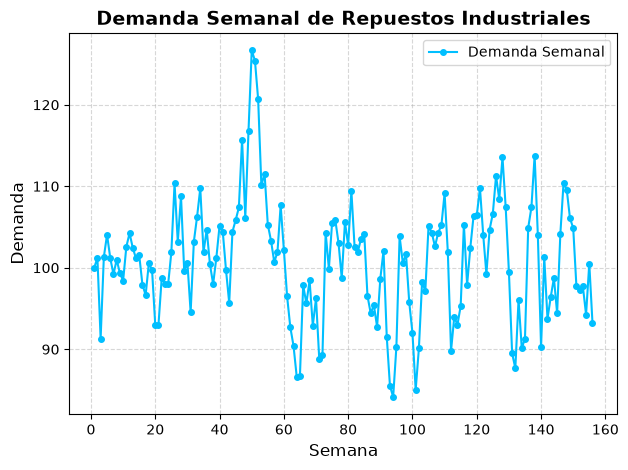

In [17]:
# Grafico Temporal
plt.plot(
    df['semana'],
    df['demanda'],
    marker='o',
    linestyle='-',
    color='deepskyblue',
    linewidth=1.5,
    markersize=4,
    label='Demanda Semanal')

# Títulos
plt.title('Demanda Semanal de Repuestos Industriales', fontsize=14, fontweight='bold')
plt.xlabel('Semana', fontsize=12)
plt.ylabel('Demanda', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

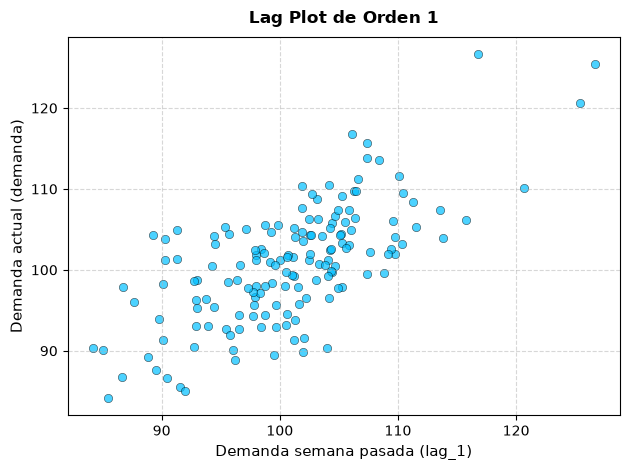

In [27]:
plt.scatter(
    df["lag_1"],
    df["demanda"],
    color='deepskyblue',
    alpha=0.7,
    edgecolors='black',
    linewidths=0.4
)

plt.title("Lag Plot de Orden 1", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Demanda semana pasada (lag_1)", fontsize=11)
plt.ylabel("Demanda actual (demanda)", fontsize=11)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Función de autocorrelación (ACF) — 1 punto

Construya una ACF de `demanda` hasta el rezago 20.

Use:

```python
plot_acf(...)
```

y omita el rezago 0 con `zero=False`.

Esta sección será revisada manualmente.


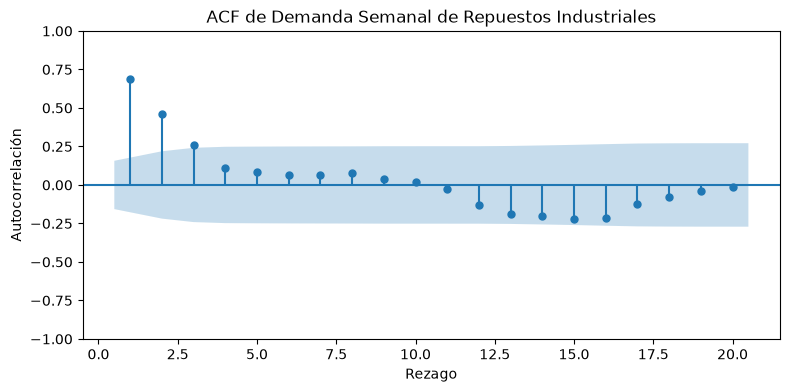

In [31]:
fig, ax = plt.subplots(figsize=(9.0, 4.0))

plot_acf(
    df['demanda'].dropna(),
    lags=20,
    zero=False,
    ax=ax
)

# Configurar títulos y etiquetas personalizados
ax.set(
    title="ACF de Demanda Semanal de Repuestos Industriales",
    xlabel="Rezago",
    ylabel="Autocorrelación"
)

plt.show()